# LAB 09 — Bias, Variance and Imbalanced Data
## Overfitting, ROC/AUC, Resampling, SMOTE and Noisy Data on Real Medical Data

## Student Information
- **Name:** Muhammad Anees
- **Student ID:** 023-24-0251
- **Section:** H
- **GitHub:** https://github.com/Anees-Memon-Hub/ML-Practice
- **Kaggle:** https://www.kaggle.com/aneesmemon
- **Dataset:** Stroke Prediction Dataset (Kaggle)
- **Dataset Source:** https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset

---

**Reading guide.** Everything uses `SEED = 42`. Every number quoted in a Markdown interpretation comes from the run directly above it. Golden rule: the imputer, scaler, resamplers and the decision threshold are learned from the **training data only**; the test set is used only for final scoring.

## Setup — imports

In [42]:
import warnings, os
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score,
                                     cross_val_predict, learning_curve)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score,
                             precision_recall_curve, average_precision_score)
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler  
SEED = 42
np.random.seed(SEED)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 100

---
## Part 0 — Setup and the Data
Load the CSV and look at its shape, missing values, gender categories and the class balance.

In [43]:
# Load the dataset (works with the common filenames)
possible_paths = [
    "healthcare-dataset-stroke-data.csv",
    "healthcare-dataset-stroke-data_1.csv",
    "healthcare-dataset-stroke-data_1(1).csv",
    "/content/healthcare-dataset-stroke-data.csv"
]

path = next((p for p in possible_paths if os.path.exists(p)), None)

if path is None:
    raise FileNotFoundError(
        "Dataset not found. Place the CSV in the notebook directory."
    )

df = pd.read_csv(path)

print("Dataset loaded successfully:", path)
print("Shape:", df.shape)

print("\nColumns with missing values:")
print(df.isna().sum()[df.isna().sum() > 0])

print("\nValue counts of gender:")
print(df["gender"].value_counts())

cnt = df["stroke"].value_counts().sort_index()
print("\nStroke = 0: %d (%.2f%%)" % (cnt[0], 100 * cnt[0] / len(df)))
print("Stroke = 1: %d (%.2f%%)" % (cnt[1], 100 * cnt[1] / len(df)))

df.head()

Dataset loaded successfully: healthcare-dataset-stroke-data_1.csv
Shape: (5110, 12)

Columns with missing values:
bmi    201
dtype: int64

Value counts of gender:
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

Stroke = 0: 4861 (95.13%)
Stroke = 1: 249 (4.87%)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


**Interpretation.** The dataset consists of 5,110 patients with 12 attributes. The only column with missing values is the `bmi` column (201 entries or 3.9%). The `gender` is Female (2,994), Male (2,115) and Other (1) hence that class cannot be learned or validated. The target variable has an imbalance of 4,861 without stroke (95.13%) vs 249 with stroke (4.87%).

### Cleaning, encoding, split, imputation and scaling
`id` is dropped (an identifier carries no medical information), the single `Other` row is removed, text columns are one-hot encoded (`drop_first=True`), then an 80/20 **stratified** split is made. The `bmi` median is learned on the train set only and applied to both sets; a `StandardScaler` fitted on train gives the scaled copy used by Logistic Regression.

In [44]:
# --- cleaning ---
df = df.drop(columns=["id"])                       # identifier, carries no medical information
df = df[df["gender"] != "Other"].reset_index(drop=True)   # only 1 row: cannot be learned or tested
print("Rows after removing 'Other' gender:", len(df))

df_enc = pd.get_dummies(df, drop_first=True, dtype=int)   # encode the text columns
X = df_enc.drop(columns="stroke")
y = df_enc["stroke"]
print("Feature columns:", list(X.columns))

# --- 80/20 stratified split ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

# --- median imputation learned on TRAIN only ---
train_median = X_train.median()
print("\nMissing before imputation  (train / test):", int(X_train.isna().sum().sum()), "/", int(X_test.isna().sum().sum()))
print("Train median of bmi:", round(train_median["bmi"], 2))
X_train = X_train.fillna(train_median)
X_test = X_test.fillna(train_median)               # test is filled with the TRAIN median
print("Missing after imputation   (train / test):", int(X_train.isna().sum().sum()), "/", int(X_test.isna().sum().sum()))

# --- scaled copy (for Logistic Regression), scaler fitted on TRAIN only ---
scaler = StandardScaler().fit(X_train)
X_train_s = pd.DataFrame(scaler.transform(X_train), columns=X.columns, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

print("\nTrain shape:", X_train.shape, " Test shape:", X_test.shape)
print("Stroke cases in TRAIN: %d of %d (%.2f%%)" % (y_train.sum(), len(y_train), 100 * y_train.mean()))
print("Stroke cases in TEST : %d of %d (%.2f%%)" % (y_test.sum(), len(y_test), 100 * y_test.mean()))

Rows after removing 'Other' gender: 5109
Feature columns: ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'gender_Male', 'ever_married_Yes', 'work_type_Never_worked', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'Residence_type_Urban', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes']

Missing before imputation  (train / test): 163 / 38
Train median of bmi: 28.1
Missing after imputation   (train / test): 0 / 0

Train shape: (4087, 15)  Test shape: (1022, 15)
Stroke cases in TRAIN: 199 of 4087 (4.87%)
Stroke cases in TEST : 50 of 1022 (4.89%)


**Interpretation.** Following the elimination of `id` column as well as the single "Other" case, there are 5,109 patients along with 15 categorical variables left. Split results in 4,087 training rows and 1,022 testing rows. There are **199 strokes** (4.87%) in training dataset and **50 strokes** (4.89%) in the testing one. Missing 163 values in `bmi` column of training dataset and missing 38 values in testing one were imputed by the *training* median value (28.1).

**Question (a) – Is the imbalance severe? Why `stratify=y`? What will happen if there are few strokes in the test set?**
The proportion is 1 stroke per 20 samples (4.87% strokes vs. 95.13% non-strokes). Stratification makes sure that the proportion of classes is the same in the train and test sets (4.87% vs. 4.89%). In a random partition, we may get fewer or more strokes in the test set (extreme case – practically no strokes at all), which will result in metrics being subject to randomness. With stratification, we still have only 50 positive samples in the test set, so each sample contributes 2 percentage points to recall.

---
## Part 1 — The Accuracy Trap
A majority-class baseline and a default Logistic Regression are compared with six metrics. The helper `evaluate()` is reused for the rest of the lab.

,Accuracy,Precision,Recall,F1,ROC AUC,PR AUC
Majority baseline,0.9511,0.0,0.00,0.0000,0.5000,0.0489
Logistic Regression,0.9521,1.0,0.02,0.0392,0.8394,0.2692


Confusion matrix of Logistic Regression (threshold 0.5)  [[TN FP], [FN TP]]:
 [[972   0]
 [ 49   1]]


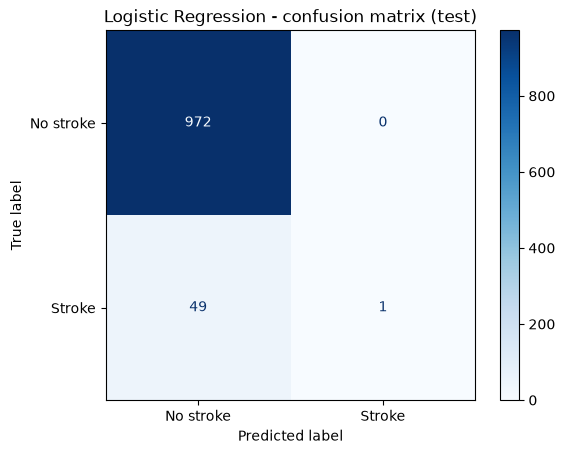

In [45]:
def evaluate(model, Xtr, ytr, Xte, yte, threshold=0.5):
    """Fit `model` on (Xtr, ytr) and return the six metrics on (Xte, yte)."""
    model.fit(Xtr, ytr)
    proba = model.predict_proba(Xte)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {"Accuracy": accuracy_score(yte, pred),
            "Precision": precision_score(yte, pred, zero_division=0),
            "Recall": recall_score(yte, pred, zero_division=0),
            "F1": f1_score(yte, pred, zero_division=0),
            "ROC AUC": roc_auc_score(yte, proba),
            "PR AUC": average_precision_score(yte, proba)}

dummy = DummyClassifier(strategy="most_frequent")
m_dummy = evaluate(dummy, X_train_s, y_train, X_test_s, y_test)

lr = LogisticRegression(max_iter=1000, random_state=SEED)
m_lr = evaluate(lr, X_train_s, y_train, X_test_s, y_test)

part1 = pd.DataFrame({"Majority baseline": m_dummy, "Logistic Regression": m_lr}).T.round(4)
display(part1)

cm = confusion_matrix(y_test, lr.predict(X_test_s))
print("Confusion matrix of Logistic Regression (threshold 0.5)  [[TN FP], [FN TP]]:\n", cm)
ConfusionMatrixDisplay(cm, display_labels=["No stroke", "Stroke"]).plot(cmap="Blues")
plt.title("Logistic Regression - confusion matrix (test)")
plt.show()

**Interpretation.** The "always predict no stroke" baseline achieves an accuracy of **0.9511** by doing nothing, whereas the default Logistic Regression achieves **0.9521**. Its confusion matrix reveals the reasons for this result: TN = 972, FP = 0, FN = 49, TP = 1. Recall is 0.02, F1 is 0.039, although ROC AUC is 0.839 and PR AUC is 0.269 (the no skill value for PR is 0.049).

**Question (a) — Compare the accuracy of the baseline and Logistic Regression.**
The accuracies are only 0.001 apart, i.e., one extra patient was correctly classified. This metric claims that the model has "excellent" performance of 95%, however, the model that does not detect strokes at all also has 95%. Accuracy is a poor choice of metric when classes are imbalanced.

**Question (b) — What does false negative mean in this case, and which values can we trust?**
False negative means that a patient will suffer from a stroke but is classified as "low-risk" and released without any precautions; this is the costliest error that can happen with this particular screening test. The model of Logistic Regression predicts 49 out of 50 strokes incorrectly. The numbers that we should trust are **recall** (0.02), **F1**, and threshold-independent **ROC AUC / PR AUC** and not accuracy.

---
## Part 2 — Underfitting, Overfitting, Bias and Variance
From now on the cross-validation score is ROC AUC.

### Task 2.1 — Validation curve (`max_depth` = 1…15 and None)

,Train AUC,CV AUC
max_depth,,
1,0.7171,0.7317
2,0.8208,0.8168
3,0.8375,0.8161
4,0.8580,0.8180
5,0.8758,0.7921
6,0.9026,0.7585
7,0.9276,0.7385
8,0.9494,0.7138
9,0.9678,0.6812


Best depth by CV AUC: 4  -> CV AUC = 0.8180


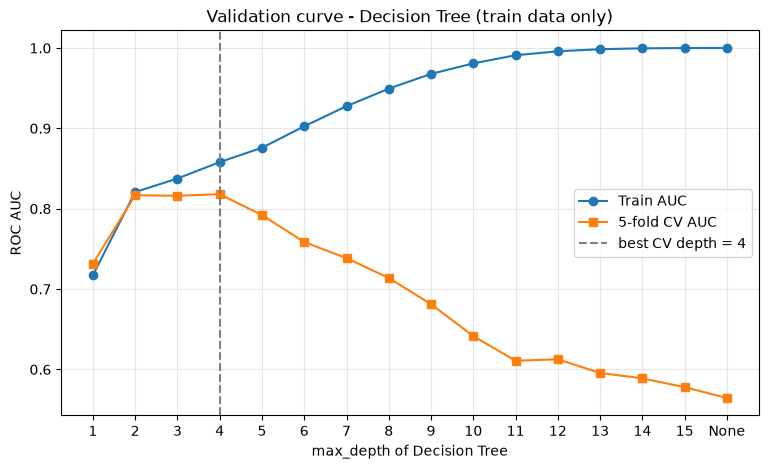

In [46]:
depths = list(range(1, 16)) + [None]
labels = [str(d) for d in depths]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

rows = []
for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=SEED)
    cv_auc = cross_val_score(tree, X_train, y_train, cv=skf, scoring="roc_auc").mean()
    tree.fit(X_train, y_train)
    tr_auc = roc_auc_score(y_train, tree.predict_proba(X_train)[:, 1])
    rows.append((str(d), tr_auc, cv_auc))
val = pd.DataFrame(rows, columns=["max_depth", "Train AUC", "CV AUC"]).set_index("max_depth")
display(val.round(4))

best_depth = val["CV AUC"].idxmax()
print("Best depth by CV AUC:", best_depth, " -> CV AUC = %.4f" % val.loc[best_depth, "CV AUC"])

plt.figure(figsize=(9, 5))
plt.plot(labels, val["Train AUC"], "o-", label="Train AUC")
plt.plot(labels, val["CV AUC"], "s-", label="5-fold CV AUC")
plt.axvline(labels.index(best_depth), color="gray", ls="--", label="best CV depth = %s" % best_depth)
plt.xlabel("max_depth of Decision Tree"); plt.ylabel("ROC AUC")
plt.title("Validation curve - Decision Tree (train data only)")
plt.legend(); plt.grid(alpha=.3); plt.show()

**Interpretation and Answer for (a).**
- **Underfitting (high bias): depth 1–2**. At depth 1, train AUC equals 0.7171 and CV AUC 0.7317. They are rather low and similar to each other, so that tree is too simple. At depth 2 (0.8208/0.8168) model becomes better.
- **Good zone, depth 3–4**. Train and CV AUCs are 0.8375/0.8161 at depth 3 and 0.8580/0.8180 at depth 4. Maximum of CV curve is at **depth 4 (CV AUC 0.8180)**.
- **Overfitting (high variance): depth >= 5**. Train AUC increases but CV AUC starts to decrease. At depth 10, train AUC is 0.9808 and CV AUC 0.6414, at depth `None`, train AUC is **1.0000** but CV AUC is **0.5644**, which is almost a random guess.

I would prefer **depth 4** (maximum of CV AUC). Depths 2, 3, and 4 are not more than 0.002 apart from each other, so that the simplest depth 3 is also statistically equivalent, which is the reason for choosing depth 3 in further analysis.

### Task 2.2 — Learning curves (depth 1 vs depth None)

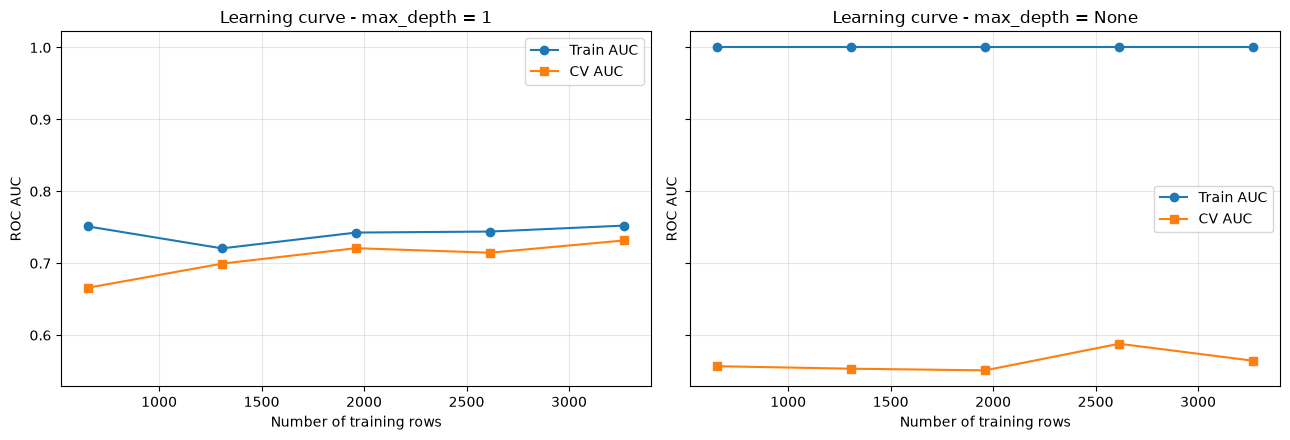

max_depth = 1


,train rows,Train AUC,CV AUC
0,653,0.7512,0.6659
1,1307,0.7206,0.6994
2,1961,0.7426,0.7209
3,2615,0.7440,0.7146
4,3269,0.7523,0.7317


max_depth = None


,train rows,Train AUC,CV AUC
0,653,1.0,0.5568
1,1307,1.0,0.5533
2,1961,1.0,0.5510
3,2615,1.0,0.5880
4,3269,1.0,0.5644


In [47]:
sizes = np.linspace(0.2, 1.0, 5)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
lc_tables = {}
for ax, d in zip(axes, [1, None]):
    ts, tr_sc, va_sc = learning_curve(DecisionTreeClassifier(max_depth=d, random_state=SEED),
                                      X_train, y_train, train_sizes=sizes, cv=skf,
                                      scoring="roc_auc", shuffle=True, random_state=SEED)
    lc_tables[d] = pd.DataFrame({"train rows": ts, "Train AUC": tr_sc.mean(axis=1), "CV AUC": va_sc.mean(axis=1)}).round(4)
    ax.plot(ts, tr_sc.mean(axis=1), "o-", label="Train AUC")
    ax.plot(ts, va_sc.mean(axis=1), "s-", label="CV AUC")
    ax.set_title("Learning curve - max_depth = %s" % d)
    ax.set_xlabel("Number of training rows"); ax.set_ylabel("ROC AUC")
    ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()
print("max_depth = 1"); display(lc_tables[1])
print("max_depth = None"); display(lc_tables[None])

**Interpretation and Question (b).**
- **Depth 1 (high bias):** For 100% of training data, the train AUC = 0.7523 and CV AUC = 0.7317. The two lines are very similar and also remain low (≈ 0.73-0.75). The model is too simple to capture the pattern, hence cannot perform well in either case.
- **Depth None (high variance):** The train AUC equals 1.0 for all sizes, while CV AUC remains between 0.55-0.59 (0.5568 at 653 rows and 0.5644 at 3,269 rows). The enormous difference of ≈ 0.44 characterizes high variance.

Differences in high bias and variance: high bias when *both* curves are low and close; high variance when there is a *big difference* between a high train and a low CV curves. Additional rows cannot help with high bias (at depth = 1 the value is constrained and should be around 0.75; more expressive model/features are needed). More data could potentially help with high variance (it could reduce the gap between train and CV curves), however, the CV curve of the unrestricted decision tree is nearly flat and, therefore, additional rows cannot save it; it needs to be regularised/averaged.

### Task 2.3 — Measure variance directly (40 bootstrap trees per depth)

In [48]:
B = 40
var_rows, avg_probs = [], {}
for d in [1, 3, None]:
    rng = np.random.RandomState(SEED)
    probs = np.zeros((B, len(X_test)))
    for b in range(B):
        idx = rng.choice(len(X_train), len(X_train), replace=True)       # bootstrap sample of TRAIN rows
        t = DecisionTreeClassifier(max_depth=d, random_state=SEED).fit(X_train.iloc[idx], y_train.iloc[idx])
        probs[b] = t.predict_proba(X_test)[:, 1]
    single_aucs = [roc_auc_score(y_test, p) for p in probs]
    var_rows.append({"max_depth": str(d),
                     "Mean prediction variance": probs.var(axis=0).mean(),
                     "Mean AUC of single trees": np.mean(single_aucs),
                     "Std of single-tree AUC": np.std(single_aucs),
                     "AUC of averaged prediction": roc_auc_score(y_test, probs.mean(axis=0))})
var_table = pd.DataFrame(var_rows).set_index("max_depth")
display(var_table.round(5))

,Mean prediction variance,Mean AUC of single trees,Std of single-tree AUC,AUC of averaged prediction
max_depth,,,,
1,0.00079,0.76173,0.01747,0.81662
3,0.00195,0.79628,0.01671,0.83004
None,0.04193,0.55391,0.02527,0.77492


**Explanation and Question (c).**
Prediction variance increases significantly with the increase of the depth: **0.00079** (depth 1), **0.00195** (depth 3), and **0.04193** (depth None), more than 53 times higher variance in the case of the unlimited tree compared to the stump. Additionally, the unlimited trees are individually weak (the mean AUC value equals 0.5539, the maximum deviation equals 0.0253).

The averaging of 40 trees works best in cases when variance is the highest: the AUC improves from 0.5539 (individual stump) to **0.7749** (average of 40 stumps), +0.221 in the case of depth None. In the case of depth 3 the AUC improves from 0.7963 to 0.8300 (+0.034) and in the case of depth 1 from 0.7617 to 0.8166 (+0.055). The averaging reduces variance but not bias and thus leaves the stump weak. It is the principle of the **Random Forest (Lab 4)** algorithm.

**Question (d) – The bias-variance trade-off explained in my own words.**
Test error is the sum of the bias, which is the error due to model being too simple, hence systematic error; and variance, which is the error due to model being too flexible, hence overly responsive to a particular training data. Increasing flexibility reduces bias while increasing variance, hence an optimal model will be at the center.
- **Depth 1:** high bias, low variance (Variance 0.0008, CV AUC 0.73) – underfitting.
- **Depth 3:** optimal – low variance (0.0020) and the optimal CV area (0.8161, very close to the maximum of 0.8180).
- **Depth None:** low bias (training AUC 1.0) but high variance (0.042) and CV AUC 0.56 – overfitting.

---
## Part 3 — ROC, AUC, Precision-Recall and Thresholds
### Task 3.1 — Compare models with curves
Logistic Regression (scaled), Decision Tree (depth 3) and Random Forest (200 trees, `min_samples_leaf=5`) trained on the original training data.

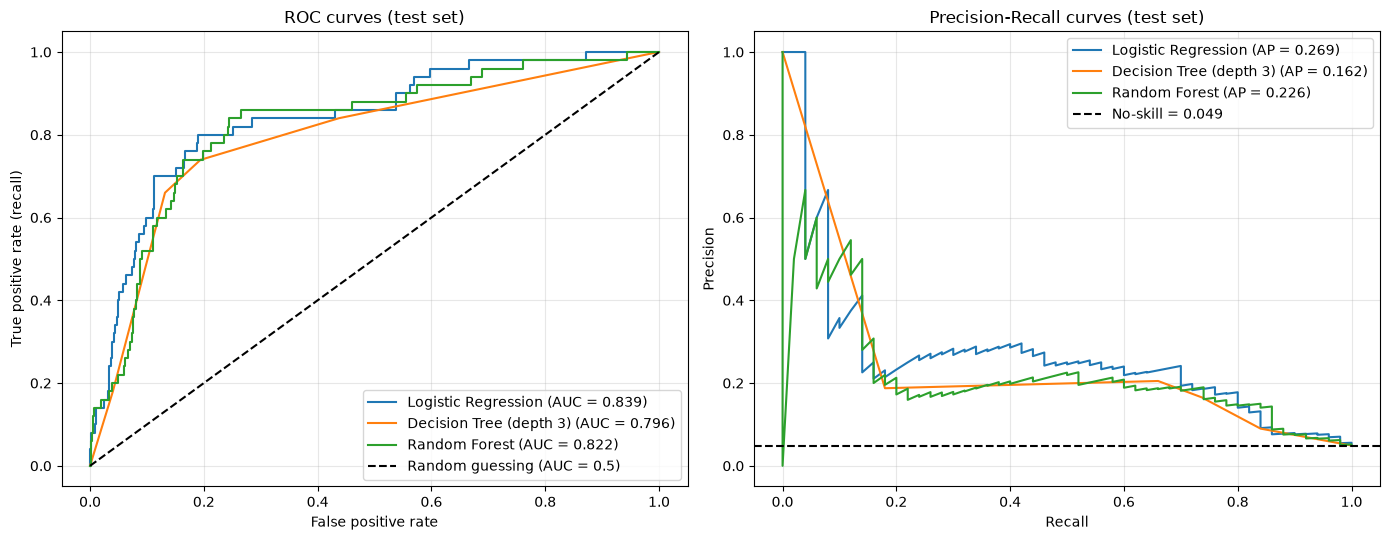

No-skill level (stroke rate in test): 0.0489


,ROC AUC,Average precision (PR AUC)
Logistic Regression,0.8394,0.2692
Decision Tree (depth 3),0.7956,0.1621
Random Forest,0.8224,0.2255


In [49]:
rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1)
models3 = {"Logistic Regression": (LogisticRegression(max_iter=1000, random_state=SEED), X_train_s, X_test_s),
           "Decision Tree (depth 3)": (DecisionTreeClassifier(max_depth=3, random_state=SEED), X_train, X_test),
           "Random Forest": (rf, X_train, X_test)}
proba3 = {}
for name, (m, Xtr, Xte) in models3.items():
    m.fit(Xtr, y_train)
    proba3[name] = m.predict_proba(Xte)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for name, p in proba3.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, label="%s (AUC = %.3f)" % (name, roc_auc_score(y_test, p)))
axes[0].plot([0, 1], [0, 1], "k--", label="Random guessing (AUC = 0.5)")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("ROC curves (test set)"); axes[0].legend(loc="lower right"); axes[0].grid(alpha=.3)

for name, p in proba3.items():
    pr, rc, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rc, pr, label="%s (AP = %.3f)" % (name, average_precision_score(y_test, p)))
noskill = y_test.mean()
axes[1].axhline(noskill, color="k", ls="--", label="No-skill = %.3f" % noskill)
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall curves (test set)"); axes[1].legend(loc="upper right"); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
print("No-skill level (stroke rate in test):", round(noskill, 4))
curve_summary = pd.DataFrame({n: {"ROC AUC": roc_auc_score(y_test, p), "Average precision (PR AUC)": average_precision_score(y_test, p)}
                              for n, p in proba3.items()}).T
display(curve_summary.round(4))

**Interpretation.** In ROC, Logistic Regression (AUC 0.839) shows the most successful results, followed by Random Forest (0.822) and the tree with the maximum depth of three (0.796); all of them are far away from the 0.5 line. The situation with PR is completely different; the average precision for Logistic Regression is 0.269, for Random Forest – 0.226, and for tree – 0.162, while the no-skill line is 0.049.

**Question (a) — How is it possible to have extremely poor recall in part 1 but an AUC of 0.839?**
AUC measures **ranking**, which is essentially the likelihood of randomly selecting a stroke case with a greater risk score than a random selection from controls. In other words, the logistic regression performs well in terms of ranking patients (0.839). Also, AUC is completely threshold-independent. On the other hand, recall depends on just one threshold, which is 0.5. With less than 5% of patients having strokes and thus the very small predicted probabilities (94% of test samples lower than 0.2 and the highest one being 0.54), it is likely nobody will cross this threshold.

**Question (b): Which curve would be more meaningful to use in this case?**
The **Precision-Recall curve**. The ROC diagonal is the no skill line for any dataset, and ROC takes into account the false positive rate, which is normalized by roughly 4,861 negative samples, so even if there are lots of false positives, the rate is still low (Task 3.2: 262 false positives is a rate of just 27%). The PR curve takes into account precision, which is directly affected by those false positives, and its no skill line is the stroke rate (0.049). It proves that while AUC ≈ 0.84 seems quite good, the AP of the best classifier is just 0.269 (5.5 times the no-skill AP).

### Task 3.2 — Choose a decision threshold (≥ 80% recall)
Out-of-fold probabilities are produced on the **training data only** (the scaler is part of a pipeline, so it is re-fitted inside each fold). The highest threshold that still gives recall ≥ 0.80 on those out-of-fold predictions is applied once to the test probabilities.

Out-of-fold recall at chosen threshold: 0.804
Chosen threshold (from TRAIN only): 0.0509

TEST, threshold = 0.0509
Recall    : 0.820
Precision : 0.135
Confusion matrix [[TN FP],[FN TP]]:
 [[710 262]
 [  9  41]]
Patients flagged: 303 of 1022  (29.6%)
False alarms: 262 (86.5% of the flagged)   Missed strokes: 9 of 50


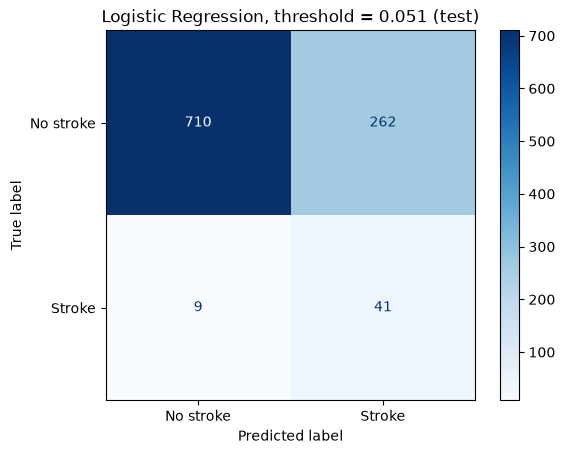

In [50]:
# Pipeline = scaler is re-fitted inside every CV fold, so nothing outside the training folds is used.
lr_pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED))
oof = cross_val_predict(lr_pipe, X_train, y_train, cv=skf, method="predict_proba")[:, 1]

prec_oof, rec_oof, thr_oof = precision_recall_curve(y_train, oof)
ok = rec_oof[:-1] >= 0.80
thr_star = thr_oof[ok].max()          # highest threshold that still gives recall >= 0.80 on the OOF predictions
print("Out-of-fold recall at chosen threshold: %.3f" % recall_score(y_train, (oof >= thr_star).astype(int)))
print("Chosen threshold (from TRAIN only): %.4f" % thr_star)

# apply to the TEST probabilities of the Logistic Regression trained in Task 3.1
p_lr = proba3["Logistic Regression"]
pred_thr = (p_lr >= thr_star).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred_thr).ravel()
print("\nTEST, threshold = %.4f" % thr_star)
print("Recall    : %.3f" % recall_score(y_test, pred_thr))
print("Precision : %.3f" % precision_score(y_test, pred_thr))
print("Confusion matrix [[TN FP],[FN TP]]:\n", np.array([[tn, fp], [fn, tp]]))
print("Patients flagged: %d of %d  (%.1f%%)" % (pred_thr.sum(), len(y_test), 100 * pred_thr.mean()))
print("False alarms: %d (%.1f%% of the flagged)   Missed strokes: %d of %d" % (fp, 100 * fp / pred_thr.sum(), fn, y_test.sum()))
ConfusionMatrixDisplay(np.array([[tn, fp], [fn, tp]]), display_labels=["No stroke", "Stroke"]).plot(cmap="Blues")
plt.title("Logistic Regression, threshold = %.3f (test)" % thr_star); plt.show()

**Interpretation.** For the out-of-fold predictions on the train data the largest threshold value with recall at least 0.80 is **0.0509** (recall for OOF 0.804). When applied to the unseen test data, it produces **recall 0.820** (41 of 50 strokes detected), precision 0.135, and the confusion matrix TN = 710, FP = 262, FN = 9, TP = 41. The hospital alerts 303 of 1,022 patients (29.6%), out of which **262 (86.5%) are false alarms**.

**Question (c) — What price does the hospital pay for the higher recall? Is it acceptable?**
This price amounts to 262 false alarms, meaning that six healthy people are alerted to every stroke discovered, and close to a third of all patients have to undergo further examination. *In favor of:* failure to alert about a stroke (9 cases instead of 49) leads to death or lifelong incapacity, while a false alarm only takes the form of measuring blood pressure or taking a blood test. *Against:* out of every 100 patients identified as potential stroke patients, 86.5 are actually healthy. This wastes time and money, causes stress, and could even overburden the clinic if the follow-up procedure is expensive or invasive. Considering that it is an inexpensive and regular procedure, I consider the tradeoff acceptable.

---
## Part 4 — Undersampling, Oversampling and SMOTE
### Task 4.1 — Compare the methods
Each method is applied to the **train set only** (Logistic Regression on the scaled data, Random Forest on the original data). The test set is never resampled; all metrics use the default 0.5 threshold.

In [51]:
def make_rf(cw=None):
    return RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED,
                                  n_jobs=-1, class_weight=cw)
def make_lr(cw=None):
    return LogisticRegression(max_iter=1000, random_state=SEED, class_weight=cw)

samplers = {"No resampling": None,
            "class_weight='balanced'": "cw",
            "Random undersampling": RandomUnderSampler(random_state=SEED),
            "Random oversampling": RandomOverSampler(random_state=SEED),
            "SMOTE": SMOTE(random_state=SEED)}

res_rows = []
for mname, maker, Xtr, Xte in [("Logistic Regression", make_lr, X_train_s, X_test_s),
                               ("Random Forest", make_rf, X_train, X_test)]:
    for sname, s in samplers.items():
        if s is None:
            Xr, yr, model = Xtr, y_train, maker()
        elif s == "cw":
            Xr, yr, model = Xtr, y_train, maker("balanced")
        else:
            Xr, yr = s.fit_resample(Xtr, y_train)         # TRAIN only
            model = maker()
        r = evaluate(model, Xr, yr, Xte, y_test)
        res_rows.append({"Model + method": "%s | %s" % (mname, sname),
                         "Train rows": len(yr), "Strokes in train": int(np.sum(yr)),
                         "Precision": r["Precision"], "Recall": r["Recall"], "F1": r["F1"],
                         "ROC AUC": r["ROC AUC"], "PR AUC": r["PR AUC"]})
resample_table = pd.DataFrame(res_rows).set_index("Model + method")
display(resample_table.round(4))

,Train rows,Strokes in train,Precision,Recall,F1,ROC AUC,PR AUC
Model + method,,,,,,,
Logistic Regression | No resampling,4087,199,1.0000,0.02,0.0392,0.8394,0.2692
Logistic Regression | class_weight='balanced',4087,199,0.1347,0.80,0.2305,0.8395,0.2595
Logistic Regression | Random undersampling,398,199,0.1246,0.82,0.2164,0.8352,0.2338
Logistic Regression | Random oversampling,7776,3888,0.1333,0.80,0.2286,0.8385,0.2646
Logistic Regression | SMOTE,7776,3888,0.1338,0.80,0.2292,0.8406,0.2876
Random Forest | No resampling,4087,199,0.0000,0.00,0.0000,0.8224,0.2255
Random Forest | class_weight='balanced',4087,199,0.1895,0.72,0.3000,0.8150,0.1987
Random Forest | Random undersampling,398,199,0.1050,0.84,0.1867,0.8203,0.2030
Random Forest | Random oversampling,7776,3888,0.1882,0.32,0.2370,0.8111,0.1906


**Interpretation of the table.** Undersampling reduces the training dataset to 398 instances (199+199). Over-sampling and SMOTE increase the training dataset size to 7,776 instances (3,888 strokes each). `class_weight='balanced'` maintains 4,087 instances and adjusts only the loss function weights.

**Question (a) — Logistic Regression: what changed and what did not?**
 recall was increased from 0.02 to 0.80 (balanced), 0.82 (undersampling), 0.80 (oversampling) and 0.80 (SMOTE), precision reduced from 1.00 (only one patient flagged) to 0.125 – 0.135, and F1 was improved from 0.039 to 0.22 – 0.23. *Not changed:* ranking quality. ROC AUC remains at the interval 0.835 – 0.841 (0.8394 without resampling) and PR AUC at the interval 0.234 – 0.288 (the largest for SMOTE 0.2876, the smallest for undersampling 0.2338 because it drops out 95% of the healthy patients). This is due to the fact that, when using a linear model, rebalancing mainly changes the intercept, thus shifting probabilities up, such that the 0.5 threshold falls at a lower point in *the same* ranking. It does the same thing as a threshold reduction in Task 3.2 (recall 0.82, precision 0.135).

**Question (b) — Did Random Forest react the same way?**
No. Random Forest behaved differently than Logistic Regression. Without any resampling, Random Forest managed 0.00 recall score. With the help of class_weight parameter set to 'balanced', there was a drastic improvement in recall score to 0.72, while random oversampling yielded 0.32. On the other hand, random undersampling provided maximum recall score (0.84), and SMOTE gave just 0.20 recall score,
and even reduced the ROC AUC from 0.8224 to 0.7668. One of the reasons could be that the Random Forest classifier has the ability to learn complex patterns, and therefore is highly dependent on changes in the training data. The synthetic samples created by SMOTE may lead to misleading patterns, as the data had many binary dummy variables.

### Task 4.2 — The classic mistake: SMOTE before the split
This is the **wrong** order, shown only to demonstrate the problem.

In [52]:
# WRONG ORDER: SMOTE on ALL the data, then split.
X_all = X.fillna(X.median())                         # (all-data median -> also a leak, part of the wrong pipeline)
X_sm, y_sm = SMOTE(random_state=SEED).fit_resample(X_all, y)
print("All data after SMOTE:", X_sm.shape, " strokes:", int(y_sm.sum()))
Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(X_sm, y_sm, test_size=0.20, stratify=y_sm, random_state=SEED)
r_wrong = evaluate(make_rf(), Xw_tr, yw_tr, Xw_te, yw_te)
print("Wrong-order test set: %d rows, %d strokes (%.0f%%)" % (len(yw_te), yw_te.sum(), 100 * yw_te.mean()))

r_right = resample_table.loc[
    "Random Forest | SMOTE",
    ["Precision", "Recall", "F1", "ROC AUC", "PR AUC"]
].to_dict()

leak_table = pd.DataFrame({
    "WRONG: SMOTE then split": {
        k: r_wrong[k] for k in ["Precision", "Recall", "F1", "ROC AUC", "PR AUC"]
    },
    "CORRECT: split then SMOTE": r_right
}).T

display(leak_table.round(4))

All data after SMOTE: (9720, 15)  strokes: 4860
Wrong-order test set: 1944 rows, 972 strokes (50%)


,Precision,Recall,F1,ROC AUC,PR AUC
WRONG: SMOTE then split,0.9290,0.9424,0.9356,0.9811,0.9761
CORRECT: split then SMOTE,0.1266,0.2000,0.1550,0.7668,0.1187


**Interpretation and Question (c).** The incorrect order yields precision 0.929, recall 0.942, F1 0.936, ROC AUC **0.981**, and PR AUC 0.976, whereas the correct order (SMOTE post-splitting) yields precision 0.127, recall 0.200, F1 0.155, ROC AUC **0.767**, and PR AUC 0.119. No improvement of any kind was made to the model itself, only the metrics were gamed.

What leaks and from where: Synthetic instances created by SMOTE are generated by interpolation between an actual stroke patient and one of his/her neighbours. If this procedure is performed for the entire dataset at once, then the synthetic instances that were created using patients that eventually ended up in the **test set** would end up in the train set (along with the neighbours of the patients in test set), thereby making the forest 'see' near-copies of the test instances. Moreover, the test set now contains near duplicates of patients in the train set, since the test set is synthetic too. The test set is also imbalanced (972 out of 1,944 rows are stroke cases, which is 50%, compared to 4.9%). The median that was used to impute `bmi` was computed for all rows. These numbers are unreliable; resampling needs to be done only on the training data.

**Question (d) — Which rebalancing approach would I pick for this hospital?**
My preference would be for **no resampling at all with a decision threshold estimated from out-of-fold predictions** (Task 3.2) and `class_weight='balanced'`, which are equal choices in my opinion. With Logistic Regression, they have exactly the same recall and precision as every other resampling technique (0.80–0.82 / 0.13) and the same AUC, yet don’t require any additional preprocessing. Undersampling discards around 3,690 of 3,888 healthy samples (95% of them) and has the smallest PR AUC; oversampling multiplies the number of samples up to 7,776, duplicating only strokes; SMOTE creates artificial patients, takes more time, harmed the performance of Random Forest (ROC AUC 0.767) and, as described in Part 5, may lead to even noisier data.

---
## Part 5 — Noisy Data
The training data is damaged on purpose; the test set is never touched. Models: Logistic Regression, Decision Tree (depth 3), Decision Tree (no limit) and Random Forest.

### Task 5.1 — Label noise (0, 5, 10, 20% of training labels flipped; 5 repeats, 1 for fraction 0)

,Logistic Regression,Decision Tree (depth 3),Decision Tree (no limit),Random Forest
Label noise fraction,,,,
0.00,0.8394,0.7956,0.5797,0.8224
0.05,0.8290,0.7957,0.5490,0.8000
0.10,0.8162,0.7950,0.5180,0.7604
0.20,0.7833,0.7762,0.5040,0.6979


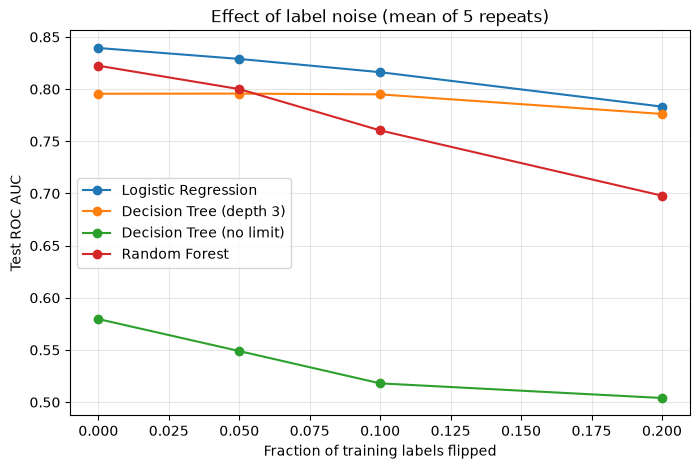

In [53]:
def flip_labels(y, fraction, rng):
    """Flip `fraction` of the labels at random (0 -> 1 and 1 -> 0)."""
    y_noisy = np.array(y).copy()
    n_flip = int(round(fraction * len(y_noisy)))
    idx = rng.choice(len(y_noisy), n_flip, replace=False)
    y_noisy[idx] = 1 - y_noisy[idx]
    return y_noisy

def noise_models():
    return {"Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
            "Decision Tree (depth 3)": DecisionTreeClassifier(max_depth=3, random_state=SEED),
            "Decision Tree (no limit)": DecisionTreeClassifier(max_depth=None, random_state=SEED),
            "Random Forest": make_rf()}

def test_auc(name, model, Xtr, ytr, Xte):
    model.fit(Xtr, ytr)
    return roc_auc_score(y_test, model.predict_proba(Xte)[:, 1])

fractions = [0, 0.05, 0.10, 0.20]
lab_res = {}
for frac in fractions:
    reps = 1 if frac == 0 else 5
    acc = {n: [] for n in noise_models()}
    for rep in range(reps):
        rng = np.random.RandomState(SEED + rep)
        yn = flip_labels(y_train, frac, rng)
        for n, m in noise_models().items():
            Xtr, Xte = (X_train_s, X_test_s) if n == "Logistic Regression" else (X_train, X_test)
            acc[n].append(test_auc(n, m, Xtr, yn, Xte))
    lab_res[frac] = {n: np.mean(v) for n, v in acc.items()}
label_table = pd.DataFrame(lab_res).T
label_table.index.name = "Label noise fraction"
display(label_table.round(4))

plt.figure(figsize=(8, 5))
for c in label_table.columns:
    plt.plot(label_table.index, label_table[c], "o-", label=c)
plt.xlabel("Fraction of training labels flipped"); plt.ylabel("Test ROC AUC")
plt.title("Effect of label noise (mean of 5 repeats)"); plt.legend(); plt.grid(alpha=.3); plt.show()

**Interpretation.** ROC AUC for test data with 0% - 20% flipped labels: Logistic Regression 0.8394 -> 0.7833, Decision Tree depth 3 0.7956 -> 0.7762, Decision Tree unlimited depth 0.5797 -> 0.5040, Random Forest 0.8224 -> **0.6979**. Depth-3 Decision Tree model is close to flat until 10% noise (0.7950) level and Logistic Regression changes gradually, but Random Forest deteriorates the most rapidly. With 20% noise level 780 people who have never had a stroke will be labeled "stroke".

### Task 5.2 — Feature noise (Gaussian noise on `age`, `avg_glucose_level`, `bmi`; levels 0, 0.5, 1, 2; 5 repeats)
At level 0 every repeat gives the identical result because nothing is changed.

,Logistic Regression,Decision Tree (depth 3),Decision Tree (no limit),Random Forest
Feature noise level,,,,
0.0,0.8394,0.7956,0.5797,0.8224
0.5,0.8338,0.7841,0.5247,0.8082
1.0,0.8130,0.7632,0.5272,0.7797
2.0,0.7733,0.7350,0.5355,0.7446


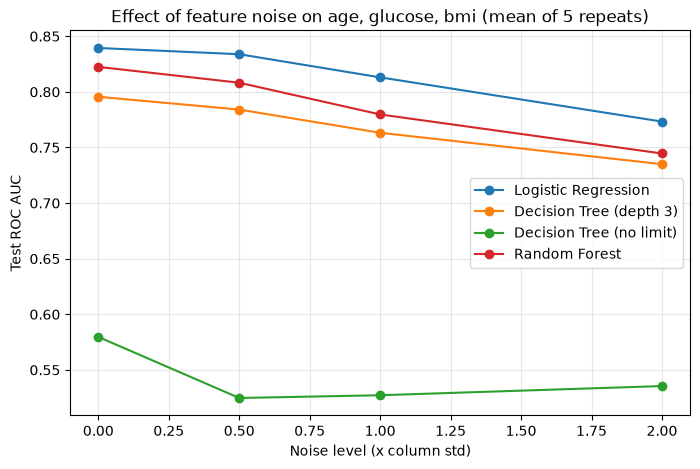

In [54]:
noisy_cols = ["age", "avg_glucose_level", "bmi"]
levels = [0, 0.5, 1, 2]
feat_res = {}
for lev in levels:
    acc = {n: [] for n in noise_models()}
    for rep in range(5):
        rng = np.random.RandomState(SEED + rep)
        Xn = X_train.copy()
        for c in noisy_cols:
            Xn[c] = Xn[c] + rng.normal(size=len(Xn)) * X_train[c].std() * lev
        sc = StandardScaler().fit(Xn)                       # scaler fitted on the NOISY training data
        Xn_s, Xte_s = sc.transform(Xn), sc.transform(X_test)
        for n, m in noise_models().items():
            if n == "Logistic Regression":
                acc[n].append(test_auc(n, m, Xn_s, y_train, Xte_s))
            else:
                acc[n].append(test_auc(n, m, Xn, y_train, X_test))
    feat_res[lev] = {n: np.mean(v) for n, v in acc.items()}
feature_table = pd.DataFrame(feat_res).T
feature_table.index.name = "Feature noise level"
display(feature_table.round(4))

plt.figure(figsize=(8, 5))
for c in feature_table.columns:
    plt.plot(feature_table.index, feature_table[c], "o-", label=c)
plt.xlabel("Noise level (x column std)"); plt.ylabel("Test ROC AUC")
plt.title("Effect of feature noise on age, glucose, bmi (mean of 5 repeats)")
plt.legend(); plt.grid(alpha=.3); plt.show()

**Interpretation.** ROC AUC testing from level 0 to level 2: Logistic Regression 0.8394 → 0.7733, Decision Tree with depth 3 0.7956 → 0.7350, Decision Tree without any depth limit 0.5797 → 0.5355, and Random Forest 0.8224 → 0.7446.
With the increase in feature noise, ROC AUC generally decreases for the effective classifiers. The Decision Tree classifier without depth limit has fluctuations as it has already started to overfit and is giving results almost as good as random guessing.

**Question (a) — Which model is most damaged by noise and which is most stable?**
For the maximal label noise level (20%) **Random Forest takes the first place on the list of damage from the useful models** (0.8224 → 0.6979, −0.125) after Logistic Regression (−0.056), while **the Decision Tree depth 3 is the most stable one** (−0.019). The unbounded tree takes −0.076 loss, yet it was almost random (0.58) anyway. For the maximal feature noise level (2) Random Forest loses again most (−0.078) while LR (−0.066) and Decision Tree depth 3 (−0.061) lose somewhat less. That corresponds to Part 2: a high-variance algorithm (deep trees even average) adjusts the wrong labels at its leaves, while the low-variance one (Decision Tree depth 3, linear one) can just adjust the general trend.

**Question (b) — Label noise or feature noise?**
For an equivalent (highest) level, the average error of the three good models is nearly identical: **0.067 for 20% label noise and 0.068 for feature noise level 2**. Neither one of them seems worse than the other; this effect depends on the model. Label noise damages the highly variable Random Forest much more (−0.125 versus −0.078), and feature noise harms simple models more (LR −0.066 versus −0.056; tree depth 3 −0.061 versus −0.019). Why? Feature noise at level 2 significantly reduces the useful information in age, avg_glucose_level and bmi, making it harder for models to distinguish between stroke and non-stroke patients. Label noise, on the other hand, directly changes the target labels, causing models to learn from incorrect outcomes. The impact depends on the model and its ability to handle noisy data.

### Task 5.3 — SMOTE and noisy labels (10% of labels flipped, 3 random draws, SMOTE applied after the noise)

In [55]:
rows = []
for mname, maker, Xtr, Xte in [("Logistic Regression", make_lr, X_train_s, X_test_s),
                               ("Random Forest", make_rf, X_train, X_test)]:
    for use_smote in [False, True]:
        pr_l, roc_l = [], []
        for rep in range(3):
            rng = np.random.RandomState(SEED + rep)
            yn = flip_labels(y_train, 0.10, rng)
            Xr, yr = Xtr, yn
            if use_smote:
                Xr, yr = SMOTE(random_state=SEED).fit_resample(Xtr, yn)   # SMOTE AFTER the noise
            m = maker().fit(Xr, yr)
            p = m.predict_proba(Xte)[:, 1]
            pr_l.append(average_precision_score(y_test, p)); roc_l.append(roc_auc_score(y_test, p))
        rows.append({"Model": mname, "Setting": "10% label noise + SMOTE" if use_smote else "10% label noise, no SMOTE",
                     "PR AUC": np.mean(pr_l), "ROC AUC": np.mean(roc_l)})
smote_noise = pd.DataFrame(rows).set_index(["Model", "Setting"])
display(smote_noise.round(4))

PR AUC  ROC AUC
Model               Setting                                   
Logistic Regression 10% label noise, no SMOTE  0.2281   0.8124
                    10% label noise + SMOTE    0.2441   0.8111
Random Forest       10% label noise, no SMOTE  0.1701   0.7588
                    10% label noise + SMOTE    0.0643   0.6176

**Interpretation and Question (c).**
For **Logistic Regression** SMOTE virtually makes no impact: PR AUC increases from 0.2281 to 0.2441, while ROC AUC changes from 0.8124 to 0.8111. In case of **Random Forest**, SMOTE does more harm than good: PR AUC decreases from 0.1701 to **0.0643** (almost the no-skill threshold 0.049), ROC AUC from 0.7588 to **0.6176**.

The reason why SMOTE magnifies label noise: it cannot differentiate a real stroke from an incorrectly labeled one. Once the flipping is done, there are hundreds of patients who have the label "stroke" but are still located in the center of the healthy group. They are treated by SMOTE as minority and generates thousands of artificial "strokes" between these points and real ones. This causes the spread of false minority labels into the healthy group and can even attract real strokes towards it. While a flexible Random Forest will create leaves for this incorrect group, a linear model is too smooth to be influenced by that.
Clean data is a must before oversampling.

---
## Part 6 — Final Decision and Conclusion
**Final choice:** Logistic Regression (standardised features, no resampling) with the decision threshold learned from out-of-fold *training* predictions (Task 3.2). The table compares it with the default 0.5 threshold on the test set.

In [56]:
final_rows = {}
def summarise(label, proba, thr):
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    final_rows[label] = {"Threshold": thr, "Precision": precision_score(y_test, pred, zero_division=0),
                         "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred, zero_division=0),
                         "Flagged": int(pred.sum()), "False alarms (FP)": int(fp), "Missed strokes (FN)": int(fn),
                         "Strokes caught (TP)": int(tp)}
summarise("Logistic Regression, default threshold 0.5", p_lr, 0.5)
summarise("Logistic Regression, train-chosen threshold", p_lr, thr_star)
final_table = pd.DataFrame(final_rows).T
for c in ["Flagged", "False alarms (FP)", "Missed strokes (FN)", "Strokes caught (TP)"]:
    final_table[c] = final_table[c].astype(int)
display(final_table.round(4))

# extra numbers used in the Executive Summary
row = final_table.iloc[1]
tp_, fp_, fn_ = int(row["Strokes caught (TP)"]), int(row["False alarms (FP)"]), int(row["Missed strokes (FN)"])
n_pos = tp_ + fn_
z = 1.96
phat = tp_ / n_pos
centre = (phat + z**2 / (2 * n_pos)) / (1 + z**2 / n_pos)
half = z * np.sqrt(phat * (1 - phat) / n_pos + z**2 / (4 * n_pos**2)) / (1 + z**2 / n_pos)
print("Chosen approach: Logistic Regression + threshold %.4f (learned from out-of-fold TRAIN predictions)" % thr_star)
print("Strokes caught %d / %d  -> recall %.3f, 95%% Wilson interval [%.2f, %.2f]" % (tp_, n_pos, phat, centre - half, centre + half))
print("False alarms per stroke caught: %.1f" % (fp_ / tp_))
print("Share of all test patients flagged: %.1f%%" % (100 * row["Flagged"] / len(y_test)))
print("Lift over random flagging (precision / stroke rate): %.1fx" % (row["Precision"] / y_test.mean()))

,Threshold,Precision,Recall,F1,Flagged,False alarms (FP),Missed strokes (FN),Strokes caught (TP)
"Logistic Regression, default threshold 0.5",0.5000,1.0000,0.02,0.0392,1,0,49,1
"Logistic Regression, train-chosen threshold",0.0509,0.1353,0.82,0.2323,303,262,9,41


Chosen approach: Logistic Regression + threshold 0.0509 (learned from out-of-fold TRAIN predictions)
Strokes caught 41 / 50  -> recall 0.820, 95% Wilson interval [0.69, 0.90]
False alarms per stroke caught: 6.4
Share of all test patients flagged: 29.6%
Lift over random flagging (precision / stroke rate): 2.8x


**Interpretation.** The model, at default threshold setting, identifies 1 patient and fails to identify 49 of 50 cases. At selected threshold level of 0.0509, the model identifies 41 patients but misses just 9, at the cost of 262 false positives rather than 0 (precision of 0.135, F1 of 0.232).

### Executive Summary
The selected classifier is **Logistic Regression with feature standardization, without any resampling, and decision threshold 0.0509** obtained based on out-of-fold predictions for achieving at least 80% recall.
When applied to an independent test set, it detects **41 of 50 strokes (recall 0.82, 95% confidence interval 0.69–0.90)** with precision 0.135 (F1 score 0.232), while the default threshold 0.5 achieves recall 0.02 (1 of 50).

The cost is **303 flagged patients (29.6%), 262 of whom were false alarms**, meaning that there are on average 6.4 false alarms per one stroke detected, and 9 cases remain undetected.
To prevent leakage, the median imputer, scaler, each of the resamplers, and the threshold are fit using only the training data, performing cross-validation within the training set and scoring only on the test set; the "SMOTE before split" experiment is provided solely for warning purposes.
Limitations: with only 50 patients having stroke in the test set, the estimate of recall has a high margin of error (one patient is equal to 2 points), while the threshold is obtained based on a single 5-fold run, implying that with another split it would be different, as well as the recall; the precision also depends on the 4.9% prevalence rate of this particular dataset and feature set.

### Final Reflection
**(a) Most surprising finding.** There were two findings: "excellent" accuracy of 95.2%, identical to the majority baseline, and the fact that all rebalancing methods provided Logistic Regression with identical ROC AUC (around 0.84) and recall/precision by just shifting the threshold. It was surprising that SMOTE worsened Random Forest's results (ROC AUC 0.822 → 0.767), as well as that reverse order SMOTE gave a false ROC AUC of 0.98.

**(b) With one more hour.** I would perform the stratified split / cross-validation several times in order to get the confidence interval of the recall and threshold. I would also perform the calibration of probabilities and selection of the threshold based on the explicit cost of the missed stroke vs the false positive. Finally, I would tune the parameters of `min_samples_leaf` and perform gradient boosting of the model.